## 参考
https://blog.csdn.net/qq_36801966/article/details/107103602

In [1]:
#! /usr/bin/python
# coding: utf-8

import os

from rdkit import Chem
from rdkit import RDConfig

from rdkit.Chem import Draw

from rdkit.Chem import FragmentCatalog

from rdkit.Chem import rdRGroupDecomposition as rdRGD
# from rdkit.Chem.Pharm2D.SigFactory import SigFactory
# from rdkit.Chem.Pharm2D import Generate, Gobbi_Pharm2D
# from rdkit.ML import InfoTheoryy

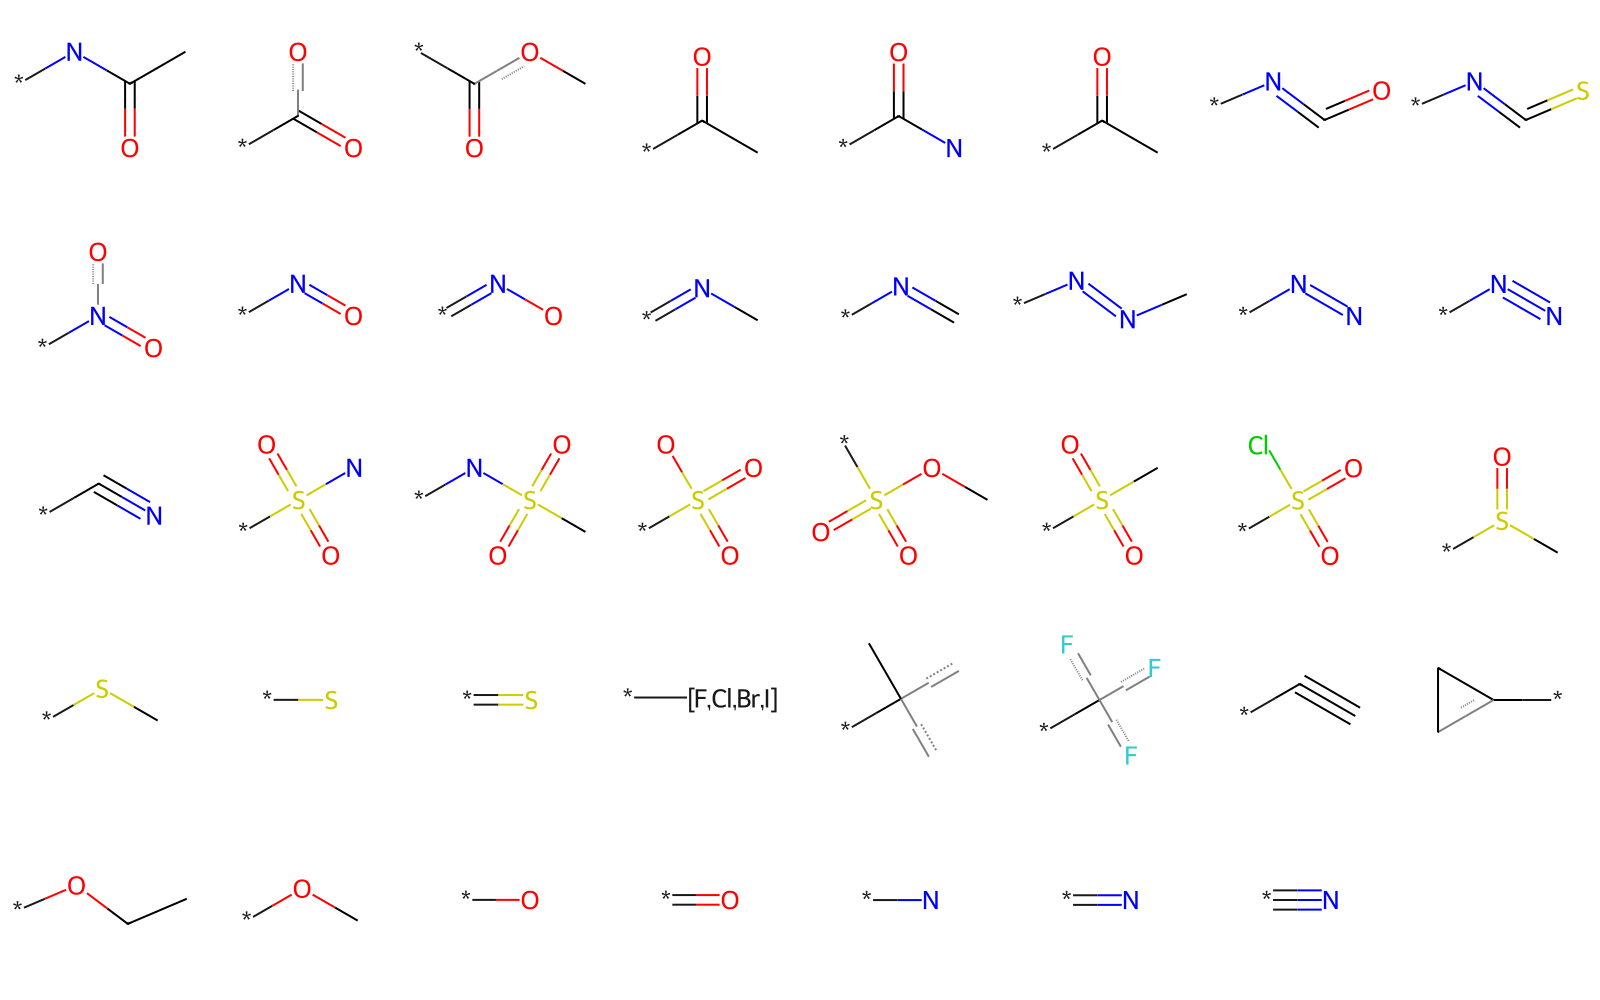

In [2]:
# 获取官能团库
# fName = os.path.join(
#     RDConfig.RDDataDir,
#     'data/FunctionalGroups.txt'
# )
fName = "FunctionalGroups.txt"

# 根据官能团库实例化一个参数器
fparams = FragmentCatalog.FragCatParams(1, 6, fName)
# 查看官能团库中包含的官能团数量
fparams_num = fparams.GetNumFuncGroups()

mols = []
# 查看每个官能团对应的集团
for i in range(fparams_num):
    mols.append(fparams.GetFuncGroup(i))

# 可视化官能团库
img = Draw.MolsToGridImage(mols, molsPerRow=8)
img

In [3]:
smiles_list = []
for i in range(fparams_num):
    smiles_list.append(Chem.MolToSmiles(fparams.GetFuncGroup(i)))
print(smiles_list)

['*NC(C)=O', '*C(O)=O', '*C(=O)OC', '*C(C)=O', '*C(N)=O', '*C(C)=O', '*N=C=O', '*N=C=S', '*N(O)=O', '*N=O', '*=NO', '*=NC', '*N=C', '*N=NC', '*N=N', '*N#N', '*C#N', '*S(N)(=O)=O', '*NS(C)(=O)=O', '*S(=O)(=O)O', '*S(=O)(=O)OC', '*S(C)(=O)=O', '*S(=O)(=O)Cl', '*S(C)=O', '*SC', '*S', '*=S', '**', '*C(C)(C)C', '*C(F)(F)F', '*C#C', '*C1CC1', '*OCC', '*OC', '*O', '*=O', '*N', '*=N', '*#N']


In [4]:
## 获取以字开头的smiles
new_smiles_list = []
for smiles in smiles_list:
    try:
        if len(Chem.MolFromSmiles(smiles).GetAtoms())<=3 and smiles[1].isalpha():
            new_smiles_list.append(smiles)
    except:
        print(smiles)
new_smiles_list

*N(O)=O
*N#N


[15:53:48] Explicit valence for atom # 1 N, 4, is greater than permitted
[15:53:48] Explicit valence for atom # 1 N, 4, is greater than permitted


['*N=O', '*N=C', '*N=N', '*C#N', '*SC', '*S', '*C#C', '*OC', '*O', '*N']